# Google Play Store Analysis

## 1. Importing Libraries

The required Python libraries are imported for data manipulation, numerical operations, and data visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

All libraries imported successfully!
Pandas: 2.1.4
NumPy: 1.25.2


## 2. Loading the Datasets

The Google Play Store apps dataset and user reviews dataset are loaded into separate Pandas DataFrames for analysis.

In [2]:
apps = pd.read_csv("dataset/googleplaystore.csv")
reviews = pd.read_csv("dataset/googleplaystore_user_reviews.csv")

print("Apps Dataset Shape:", apps.shape)
print("Reviews Dataset Shape:", reviews.shape)

Apps Dataset Shape: (10841, 13)
Reviews Dataset Shape: (64295, 5)


## 3. Initial Data Inspection

The datasets are inspected to understand their structure, column names, data types, and sample records.

In [3]:
print("Apps Dataset:")
display(apps.head())

print("\nReviews Dataset:")
display(reviews.head())

print("\nApps Dataset Information:")
apps.info()

print("\nReviews Dataset Information:")
reviews.info()

Apps Dataset:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up



Reviews Dataset:


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000



Apps Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB

Reviews Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns)

## 4. Data Quality Assessment

Missing values and duplicate records are examined in both datasets to identify data quality issues before cleaning.

In [4]:
print("Apps Dataset")
print("Missing Values:\n", apps.isnull().sum())
print("Duplicate Rows:", apps.duplicated().sum())

print("\nReviews Dataset")
print("Missing Values:\n", reviews.isnull().sum())
print("Duplicate Rows:", reviews.duplicated().sum())

Apps Dataset
Missing Values:
 App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64
Duplicate Rows: 483

Reviews Dataset
Missing Values:
 App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64
Duplicate Rows: 33616


## 5. Data Cleaning

Duplicate records are removed from both datasets. Reviews without text are excluded, while missing values in the apps dataset are handled separately.

In [5]:
# Remove duplicate rows
apps = apps.drop_duplicates()
reviews = reviews.drop_duplicates()

# Remove reviews with missing text
reviews = reviews.dropna(subset=["Translated_Review"])

print("Apps Dataset Shape After Removing Duplicates:", apps.shape)
print("Reviews Dataset Shape After Cleaning:", reviews.shape)

print("\nRemaining Missing Values in Apps:")
print(apps.isnull().sum())

print("\nRemaining Missing Values in Reviews:")
print(reviews.isnull().sum())

Apps Dataset Shape After Removing Duplicates: (10358, 13)
Reviews Dataset Shape After Cleaning: (29692, 5)

Remaining Missing Values in Apps:
App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Remaining Missing Values in Reviews:
App                       0
Translated_Review         0
Sentiment                 0
Sentiment_Polarity        0
Sentiment_Subjectivity    0
dtype: int64


### 5.1 Handling Missing Values

Missing ratings are replaced with the median, rows with missing Type or Content Rating are removed, and missing version details are filled with "Unknown".

In [6]:
# Fill missing ratings with median
apps["Rating"] = apps["Rating"].fillna(apps["Rating"].median())

# Remove rows with missing Type or Content Rating
apps = apps.dropna(subset=["Type", "Content Rating"])

# Fill missing version details
apps["Current Ver"] = apps["Current Ver"].fillna("Unknown")
apps["Android Ver"] = apps["Android Ver"].fillna("Unknown")

print("Remaining Missing Values:")
print(apps.isnull().sum())

print("\nFinal Apps Dataset Shape:", apps.shape)

Remaining Missing Values:
App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64

Final Apps Dataset Shape: (10356, 13)


### 5.2 Data Type Conversion

Text-based numerical columns such as Reviews, Installs, Price, and Size are cleaned and converted into appropriate numeric formats for analysis.

In [7]:
# Convert Reviews to numeric
apps["Reviews"] = pd.to_numeric(apps["Reviews"], errors="coerce")

# Convert Installs to numeric
apps["Installs"] = apps["Installs"].str.replace(",", "", regex=False)
apps["Installs"] = apps["Installs"].str.replace("+", "", regex=False)
apps["Installs"] = pd.to_numeric(apps["Installs"], errors="coerce")

# Convert Price to numeric
apps["Price"] = apps["Price"].str.replace("$", "", regex=False)
apps["Price"] = pd.to_numeric(apps["Price"], errors="coerce")

# Convert Size to MB
def convert_size(size):
    if size.endswith("M"):
        return float(size[:-1])
    elif size.endswith("k"):
        return float(size[:-1]) / 1024
    else:
        return np.nan

apps["Size"] = apps["Size"].apply(convert_size)

print(apps[["Reviews", "Installs", "Price", "Size"]].dtypes)
print("\nSample Converted Values:")
display(apps[["Reviews", "Installs", "Price", "Size"]].head())

Reviews       int64
Installs      int64
Price       float64
Size        float64
dtype: object

Sample Converted Values:


,Reviews,Installs,Price,Size
0,159,10000,0.0,19.0
1,967,500000,0.0,14.0
2,87510,5000000,0.0,8.7
3,215644,50000000,0.0,25.0
4,967,100000,0.0,2.8


In [8]:
print("Missing Values:")
print(apps[["Reviews", "Installs", "Price", "Size"]].isnull().sum())

print("\nDataset Summary:")
display(apps[["Reviews", "Installs", "Price", "Size"]].describe())

Missing Values:
Reviews        0
Installs       0
Price          0
Size        1525
dtype: int64

Dataset Summary:


,Reviews,Installs,Price,Size
count,1.035600e+04,1.035600e+04,10356.000000,8831.000000
mean,4.059438e+05,1.415913e+07,1.030900,21.287413
std,2.696905e+06,8.024331e+07,16.279408,22.540591
min,0.000000e+00,0.000000e+00,0.000000,0.008301
25%,3.200000e+01,1.000000e+03,0.000000,4.700000
50%,1.683000e+03,1.000000e+05,0.000000,13.000000
75%,4.643825e+04,1.000000e+06,0.000000,29.000000
max,7.815831e+07,1.000000e+09,400.000000,100.000000


### 5.3 Handling Missing App Sizes

App sizes listed as "Varies with device" are converted to missing values and replaced with the median app size.

In [9]:
apps["Size"] = apps["Size"].fillna(apps["Size"].median())

print("Missing Size Values:", apps["Size"].isnull().sum())
print("Median App Size:", apps["Size"].median(), "MB")
print("Final Apps Dataset Shape:", apps.shape)

Missing Size Values: 0
Median App Size: 13.0 MB
Final Apps Dataset Shape: (10356, 13)


## 6. Exploratory Data Analysis (EDA)

### 6.1 App Category Distribution

The number of apps in each category is analyzed to identify popular and highly saturated categories in the Google Play Store.

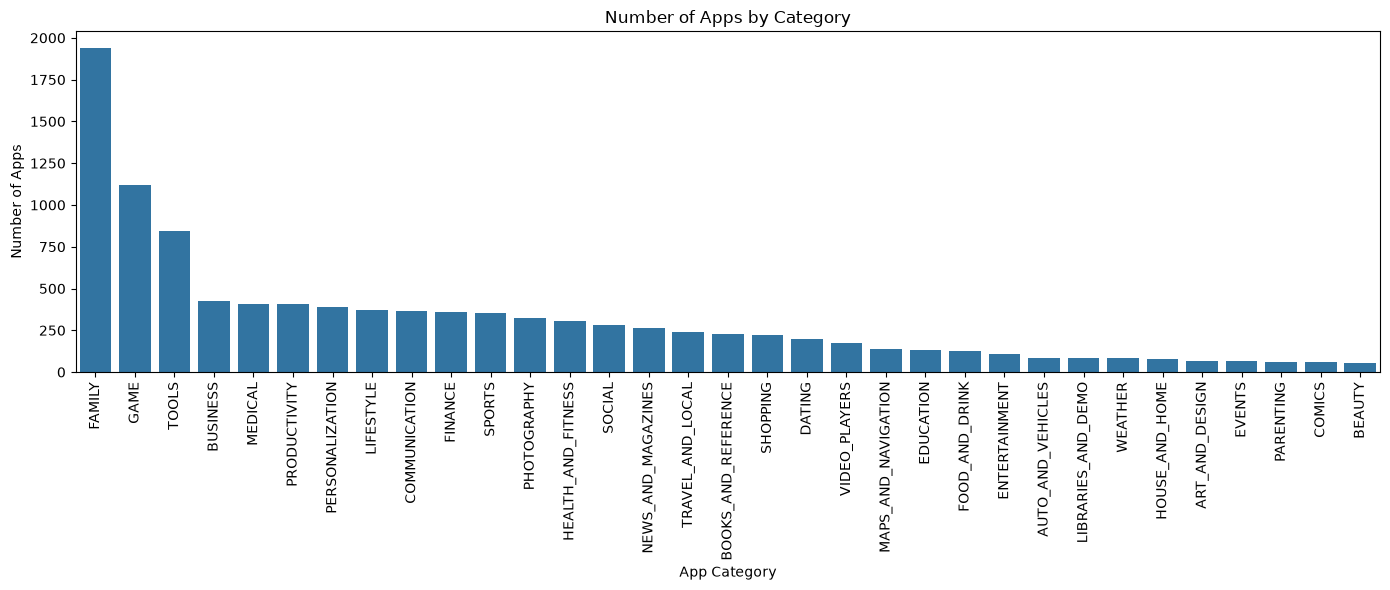

Top 5 Categories:


Category
FAMILY      1942
GAME        1121
TOOLS        843
BUSINESS     427
MEDICAL      408
Name: count, dtype: int64

In [10]:
category_counts = apps["Category"].value_counts()

plt.figure(figsize=(14, 6))
sns.barplot(x=category_counts.index, y=category_counts.values)

plt.title("Number of Apps by Category")
plt.xlabel("App Category")
plt.ylabel("Number of Apps")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Top 5 Categories:")
display(category_counts.head(5))

### 6.2 App Rating Distribution

The distribution of app ratings is analyzed to understand overall user satisfaction and identify the most common rating ranges.

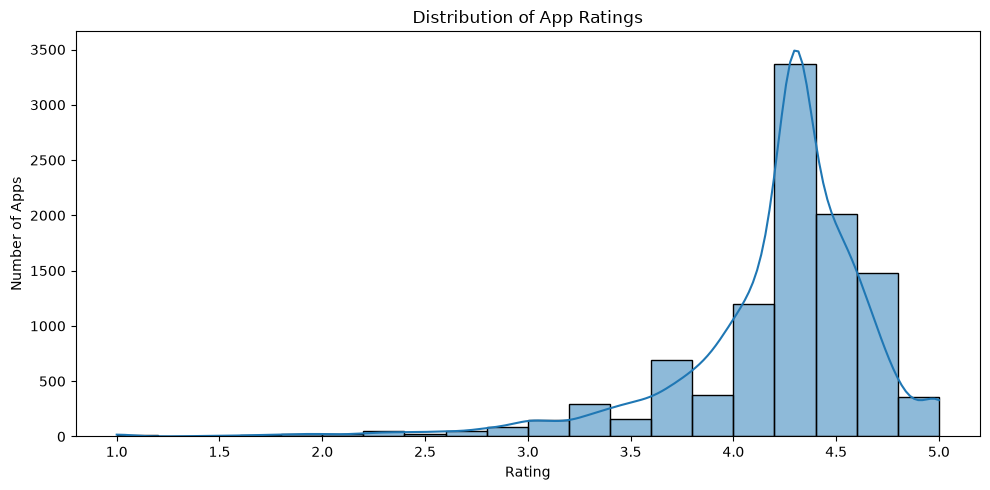

Average App Rating: 4.2
Median App Rating: 4.3


In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(apps["Rating"], bins=20, kde=True)

plt.title("Distribution of App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

print("Average App Rating:", round(apps["Rating"].mean(), 2))
print("Median App Rating:", round(apps["Rating"].median(), 2))

### 6.3 Average Rating by Category

Average app ratings are compared across categories to identify areas with higher user satisfaction.

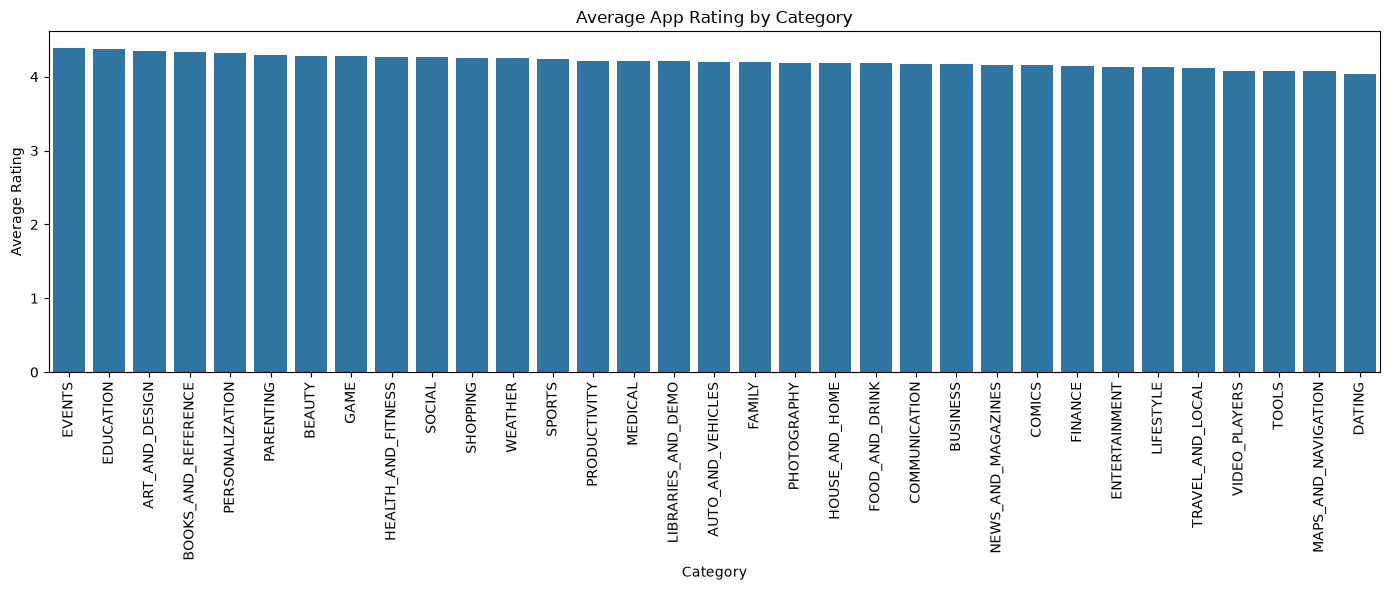

Top 5 Categories by Average Rating:


Category
EVENTS                 4.40
EDUCATION              4.38
ART_AND_DESIGN         4.36
BOOKS_AND_REFERENCE    4.34
PERSONALIZATION        4.33
Name: Rating, dtype: float64

In [12]:
category_ratings = apps.groupby("Category")["Rating"].mean().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x=category_ratings.index, y=category_ratings.values)

plt.title("Average App Rating by Category")
plt.xlabel("Category")
plt.ylabel("Average Rating")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Top 5 Categories by Average Rating:")
display(category_ratings.head(5).round(2))

### 6.4 App Size vs. Installs

The relationship between app size and installation count is examined using a scatter plot and correlation analysis.

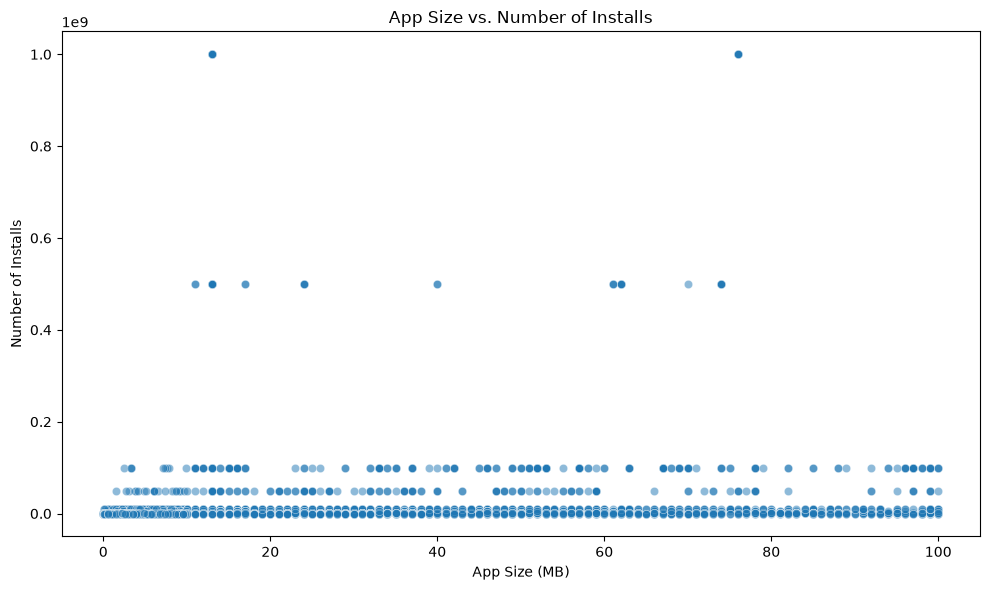

Correlation between Size and Installs: 0.05


In [13]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=apps, x="Size", y="Installs", alpha=0.5)

plt.title("App Size vs. Number of Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Number of Installs")
plt.tight_layout()
plt.show()

correlation = apps["Size"].corr(apps["Installs"])
print("Correlation between Size and Installs:", round(correlation, 3))

### 6.5 Free vs. Paid Apps

The distribution of free and paid applications is analyzed to understand the pricing trends in the Google Play Store.

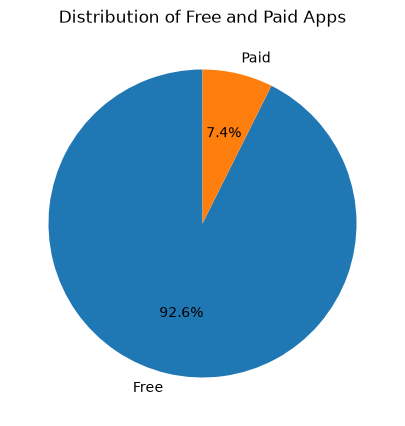

Free vs Paid Apps:


Type
Free    9591
Paid     765
Name: count, dtype: int64

In [14]:
type_counts = apps["Type"].value_counts()

plt.figure(figsize=(7, 5))
plt.pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", startangle=90)

plt.title("Distribution of Free and Paid Apps")
plt.show()

print("Free vs Paid Apps:")
display(type_counts)

### 6.6 Paid App Price Distribution

The pricing distribution of paid applications is examined to understand common price ranges and identify expensive applications.

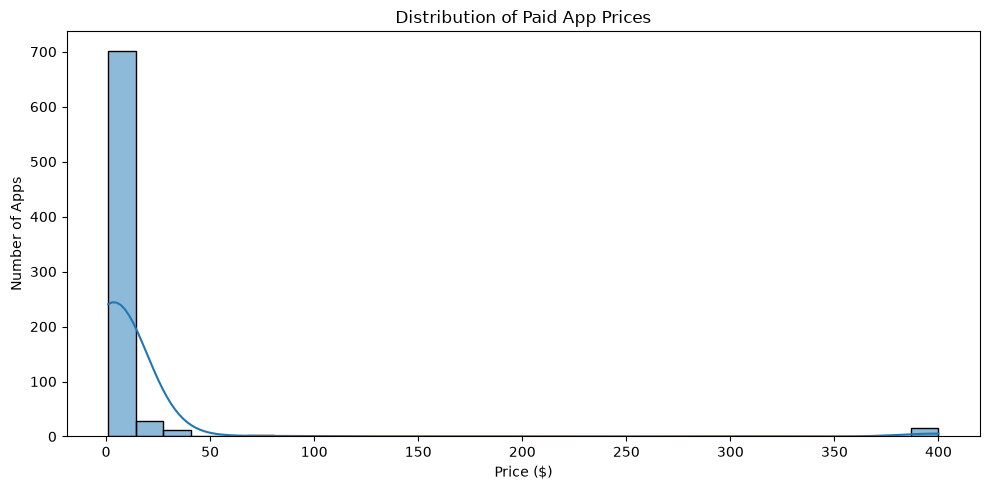

Average Paid App Price: $ 13.96
Median Paid App Price: $ 2.99
Maximum App Price: $ 400.0


In [15]:
paid_apps = apps[apps["Type"] == "Paid"]

plt.figure(figsize=(10, 5))
sns.histplot(paid_apps["Price"], bins=30, kde=True)

plt.title("Distribution of Paid App Prices")
plt.xlabel("Price ($)")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

print("Average Paid App Price: $", round(paid_apps["Price"].mean(), 2))
print("Median Paid App Price: $", round(paid_apps["Price"].median(), 2))
print("Maximum App Price: $", paid_apps["Price"].max())

### 6.7 Estimated Revenue by Category

Potential gross revenue is estimated by multiplying paid app prices by their install counts. Revenue estimates are aggregated by category to identify potentially profitable app categories.

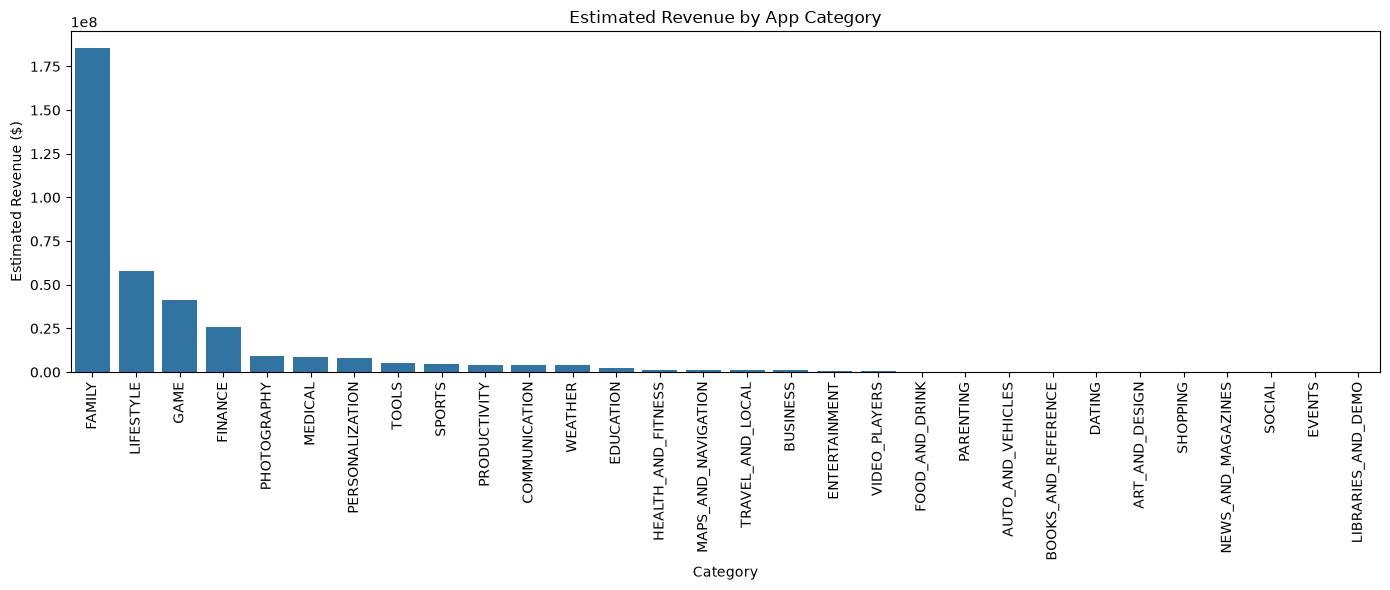

Top 5 Categories by Estimated Revenue:


Category
FAMILY         1.857803e+08
LIFESTYLE      5.758394e+07
GAME           4.098764e+07
FINANCE        2.572668e+07
PHOTOGRAPHY    8.942768e+06
Name: Estimated Revenue, dtype: float64

In [16]:
paid_apps = apps[apps["Type"] == "Paid"].copy()

paid_apps["Estimated Revenue"] = paid_apps["Price"] * paid_apps["Installs"]

category_revenue = paid_apps.groupby("Category")["Estimated Revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x=category_revenue.index, y=category_revenue.values)

plt.title("Estimated Revenue by App Category")
plt.xlabel("Category")
plt.ylabel("Estimated Revenue ($)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Top 5 Categories by Estimated Revenue:")
display(category_revenue.head(5))

In [17]:
%pip install textblob

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\dhanu\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## 7. Sentiment Analysis

### 7.1 Review Sentiment Classification

TextBlob is used to analyze review text and classify user opinions as positive, negative, or neutral based on sentiment polarity.

In [18]:
from textblob import TextBlob

def get_sentiment(review):
    polarity = TextBlob(review).sentiment.polarity

    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    else:
        return "Neutral"

reviews["Analyzed_Sentiment"] = reviews["Translated_Review"].apply(get_sentiment)

print("Sentiment Classification:")
display(reviews["Analyzed_Sentiment"].value_counts())

Sentiment Classification:


Analyzed_Sentiment
Positive    19015
Negative     6321
Neutral      4356
Name: count, dtype: int64

### 7.2 Overall Sentiment Distribution

The distribution of positive, negative, and neutral reviews is visualized to understand overall user opinions about Google Play Store applications.

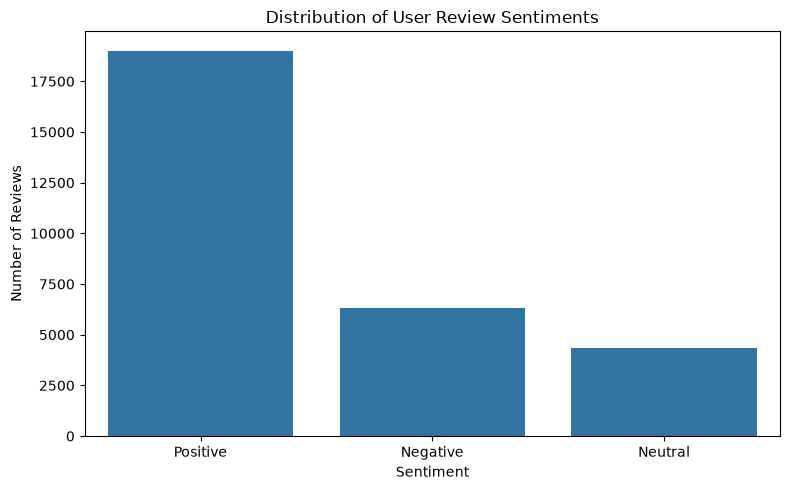

Sentiment Percentages:


Analyzed_Sentiment
Positive    64.04
Negative    21.29
Neutral     14.67
Name: count, dtype: float64

In [19]:
sentiment_counts = reviews["Analyzed_Sentiment"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values)

plt.title("Distribution of User Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

print("Sentiment Percentages:")
display((sentiment_counts / len(reviews) * 100).round(2))

### 7.3 Sentiment Analysis by Category

User reviews are combined with app categories to compare sentiment patterns across different application categories.

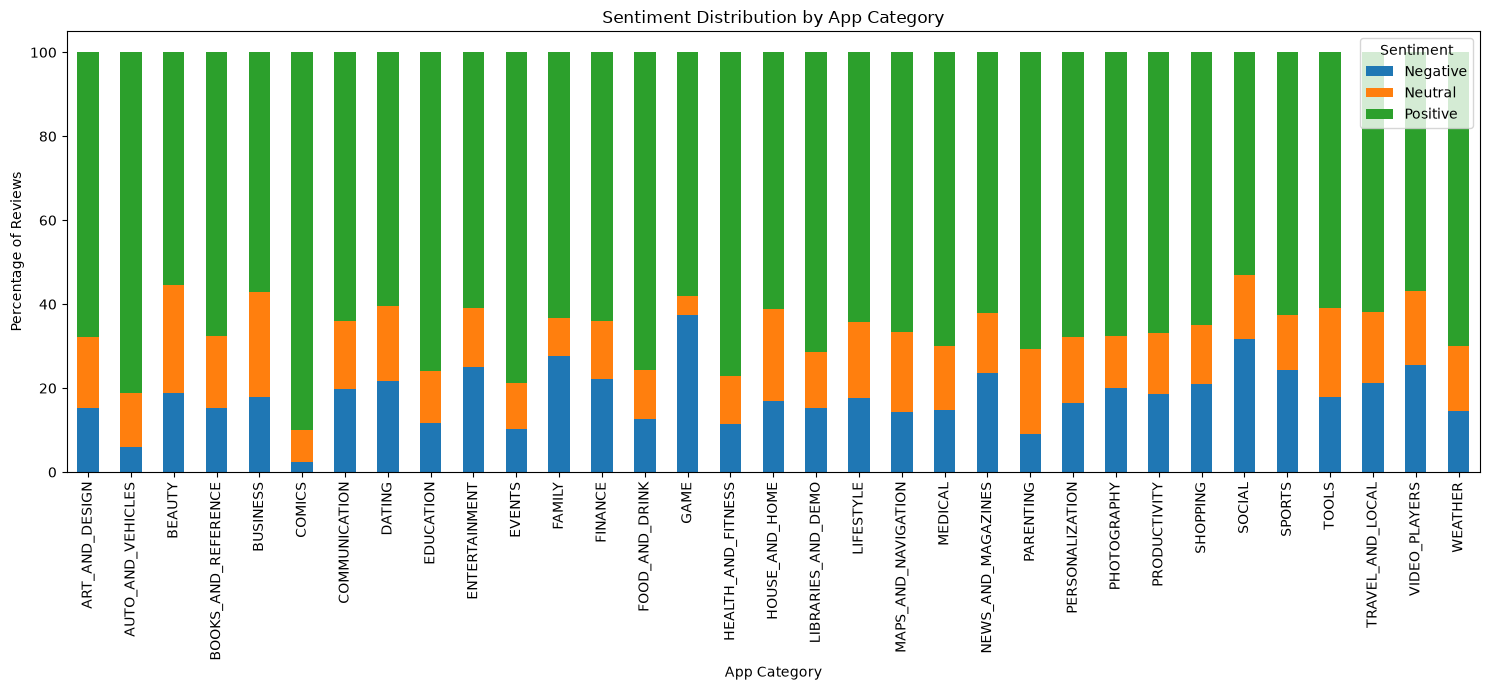

Top Categories by Positive Sentiment:


Analyzed_Sentiment,Negative,Neutral,Positive
Category,,,
COMICS,2.50,7.50,90.00
AUTO_AND_VEHICLES,6.01,12.72,81.27
EVENTS,10.26,10.90,78.85
HEALTH_AND_FITNESS,11.39,11.49,77.12
EDUCATION,11.80,12.21,75.98


In [20]:
# Merge reviews with app categories
merged_reviews = reviews.merge(
    apps[["App", "Category"]],
    on="App",
    how="inner"
)

# Calculate sentiment percentages by category
sentiment_by_category = pd.crosstab(
    merged_reviews["Category"],
    merged_reviews["Analyzed_Sentiment"],
    normalize="index"
) * 100

# Plot sentiment distribution
sentiment_by_category.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 7)
)

plt.title("Sentiment Distribution by App Category")
plt.xlabel("App Category")
plt.ylabel("Percentage of Reviews")
plt.xticks(rotation=90)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

print("Top Categories by Positive Sentiment:")
display(sentiment_by_category.sort_values("Positive", ascending=False).head(5).round(2))

In [21]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\dhanu\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


### 8. Interactive Visualization

An interactive chart is created using Plotly to explore the number of apps across different categories.

In [22]:
import plotly.express as px

category_counts = apps["Category"].value_counts().reset_index()
category_counts.columns = ["Category", "App Count"]

fig = px.bar(
    category_counts,
    x="Category",
    y="App Count",
    title="Number of Apps by Category",
    hover_data=["App Count"]
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()

## 9. Key Insights and Conclusion

1. FAMILY, GAME and TOOLS are the most common app categories, with FAMILY having the highest number of apps.
2. The average app rating is 4.2, indicating generally positive user ratings.
3. Free apps dominate the market, accounting for 92.6% of the apps.
4. COMICS received the highest percentage of positive reviews (90%).
5. FAMILY generated the highest estimated revenue among paid app categories, at approximately $185.78 million.

The analysis highlights app distribution, pricing patterns, ratings and user sentiment in the Google Play Store. These findings provide insights into app market trends and user preferences.